# 10 · Q2 SKU consolidation: before vs after

Proves consolidation does not change unit totals, then compares the fragmented (per-SKU) and consolidated views of Pop-Tarts.

In [1]:
import os
import pandas as pd
import numpy as np

DATA_DIR = next(d for d in ('data', '../data', '../../data') if os.path.isdir(d))
MISSING_TOKENS = {'', 'null', 'n/a', 'na', 'nan', 'none'}
DECISION_LOG = []

def log_decision(step, decision, rows_touched, rows_before=None, rows_after=None):
    DECISION_LOG.append({'step': step, 'decision': decision, 'rows_touched': int(rows_touched),
                         'rows_before': rows_before, 'rows_after': rows_after})


In [2]:
CATEGORY_MAP = {
    'alcohol': 'Alcohol', 'alcoholic beverages': 'Alcohol',
    'baby': 'Baby', 'baby products': 'Baby',
    'breakfast': 'Breakfast', 'breakfast foods': 'Breakfast',
    'electronics': 'Electronics',
    'emergency': 'Emergency', 'emergency supplies': 'Emergency',
    'entertainment': 'Entertainment', 'games & entertainment': 'Entertainment',
    'grocery': 'Grocery', 'groceries': 'Grocery',
    'health': 'Health', 'health & wellness': 'Health',
    'household': 'Household', 'household essentials': 'Household',
    'snacks': 'Snacks',
}
TS_FORMATS = ['%Y-%m-%d %H:%M:%S', '%Y-%m-%dT%H:%M:%S', '%m/%d/%Y %H:%M',
              '%d-%b-%Y %H:%M', '%m-%d-%Y %H:%M:%S']

def load_transactions():
    return pd.read_csv(os.path.join(DATA_DIR, 'walmart_transactions.csv'), dtype=str)

def standardize_missing(df):
    """Strip whitespace; turn '', NULL, N/A, NaN... into real NaN."""
    out = df.copy()
    touched = 0
    for c in out.columns:
        s = out[c].str.strip()
        newly_na = s.str.lower().isin(MISSING_TOKENS) & out[c].notna()
        touched += int(newly_na.sum())
        out[c] = s.mask(newly_na)
    log_decision('missing', 'strip whitespace; blank/NULL/N-A tokens -> NaN (cells, not rows)', touched, len(df), len(out))
    return out

def remove_duplicates(df):
    n0 = len(df)
    out = df.drop_duplicates()
    log_decision('duplicates', 'drop exact duplicate rows (keep first)', n0 - len(out), n0, len(out))
    n1 = len(out)
    out = out.drop_duplicates('transaction_id')
    log_decision('duplicates', 'drop repeated transaction_id (keep first)', n1 - len(out), n1, len(out))
    return out

def clean_unit_price(df):
    out = df.copy()
    raw = out['unit_price']
    dollar = int(raw.str.contains('$', regex=False, na=False).sum())
    out['unit_price'] = pd.to_numeric(raw.str.replace('$', '', regex=False).str.replace(',', '', regex=False), errors='coerce')
    bad = int(out['unit_price'].isna().sum() - raw.isna().sum())
    log_decision('unit_price', "remove '$', cast text -> float", dollar, len(df), len(out))
    log_decision('unit_price', 'values that still failed numeric cast -> NaN', bad, len(df), len(out))
    return out

def clean_quantity(df):
    out = df.copy()
    out['quantity'] = pd.to_numeric(out['quantity'], errors='coerce')
    n0 = len(out)
    out = out[out['quantity'] > 0]
    log_decision('quantity', 'drop rows with negative/zero/unparseable quantity (entry errors; sign-flip not assumed)', n0 - len(out), n0, len(out))
    return out

def parse_timestamps(df):
    out = df.copy()
    ts = pd.Series(pd.NaT, index=out.index, dtype='datetime64[ns]')
    for fmt in TS_FORMATS:
        todo = ts.isna() & out['timestamp'].notna()
        ts[todo] = pd.to_datetime(out.loc[todo, 'timestamp'], format=fmt, errors='coerce')
    unparsed = int((ts.isna() & out['timestamp'].notna()).sum())
    missing = int(out['timestamp'].isna().sum())
    out['timestamp'] = ts
    log_decision('timestamp', f'parse {len(TS_FORMATS)} mixed formats into one datetime (naive local time); {unparsed} unparseable', int(ts.notna().sum()), len(df), len(out))
    log_decision('timestamp', 'missing timestamps kept (NaT) but excluded from any date-based analysis; not imputed', missing, len(df), len(out))
    return out

def clean_store_id(df):
    out = df.copy()
    raw = out['store_id']
    out['store_id'] = (raw.str.upper().str.replace('_', '-', regex=False)
                          .str.replace(r'^FL-?(\d{3})$', r'FL-\1', regex=True))
    log_decision('store_id', "uppercase, strip, '_'/missing '-' -> canonical 'FL-###'", int((raw != out['store_id']).sum()), len(df), len(out))
    return out

def clean_category(df):
    out = df.copy()
    raw = out['category']
    out['category'] = raw.str.lower().map(CATEGORY_MAP)
    log_decision('category', f'collapse {raw.nunique()} spellings into {out["category"].nunique()} canonical categories', int((raw != out['category']).sum()), len(df), len(out))
    return out

def clean_transactions():
    DECISION_LOG.clear()
    df = load_transactions()
    for step in (standardize_missing, remove_duplicates, clean_unit_price, clean_quantity,
                 parse_timestamps, clean_store_id, clean_category):
        df = step(df)
    df['product_name_raw'] = df['product_name']
    return df.reset_index(drop=True)


In [3]:
def build_sku_map(df):
    """Group SKUs that share product names (union-find over sku <-> normalized name)."""
    names = df[['sku', 'product_name']].dropna().assign(name=lambda d: d['product_name'].str.lower().str.strip())
    parent = {}
    def find(x):
        parent.setdefault(x, x)
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    for sku, name in names[['sku', 'name']].drop_duplicates().itertuples(index=False):
        parent[find(('sku', sku))] = find(('name', name))
    names['group'] = names['sku'].map(lambda s: find(('sku', s)))
    sku_group = names.drop_duplicates('sku').set_index('sku')['group']
    ids = {g: i + 1 for i, g in enumerate(sorted(sku_group.unique(), key=str))}
    # canonical name = most common mixed-case product_name in the group (skips ALL-CAPS / lowercase variants)
    mixed = names[~names['product_name'].str.isupper() & ~names['product_name'].str.islower()]
    top_name = (mixed.assign(pid=mixed['group'].map(ids)).groupby('pid')['product_name']
                .agg(lambda s: s.str.strip().value_counts().idxmax()))
    out = pd.DataFrame({'sku': sku_group.index, 'canonical_id': sku_group.map(ids).values})
    out['canonical_name'] = out['canonical_id'].map(top_name)
    return out.sort_values(['canonical_id', 'sku']).reset_index(drop=True)


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

tx_clean = clean_transactions()
dated = tx_clean.dropna(subset=['timestamp']).assign(day=lambda x: x['timestamp'].dt.normalize())
print('rows used (have a timestamp):', len(dated), 'of', len(tx_clean))


rows used (have a timestamp): 24521 of 25402


unit totals unchanged by consolidation: 49584 units | 25402 rows
distinct SKUs: 45 -> canonical products: 20
largest consolidated family: Pop-Tarts Strawberry (4 SKUs)

Pop-Tarts avg daily units: best single SKU 44.4 vs consolidated 166.8 (3.8x)
rank among 45 SKUs, per Pop-Tarts SKU: [8, 12, 17, 18]  |  rank among 20 products, consolidated: 2


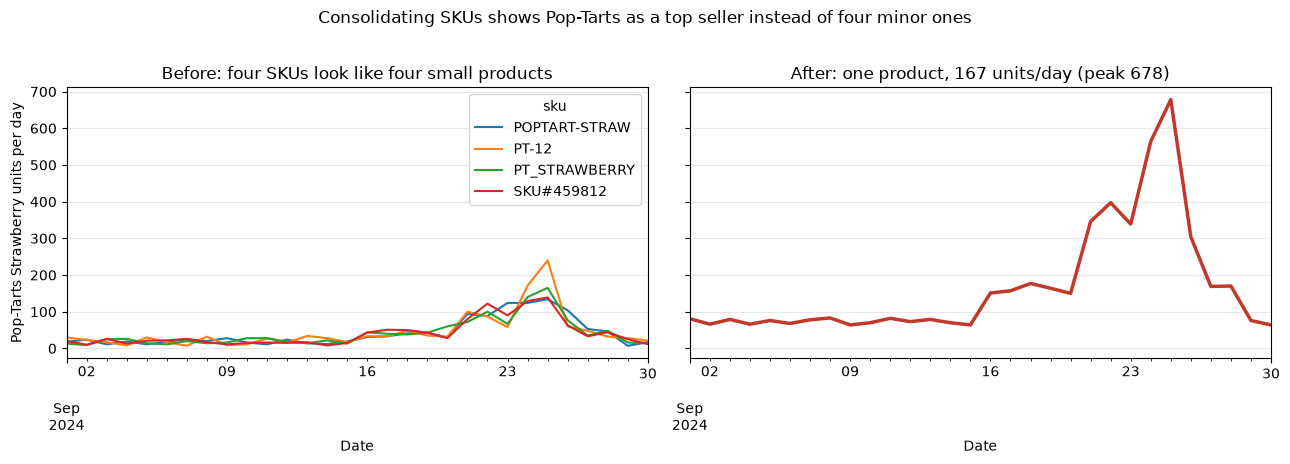

In [5]:
sku_map = build_sku_map(tx_clean)
tx_sku = tx_clean.merge(sku_map, on='sku', how='left')
assert len(tx_sku) == len(tx_clean) and tx_sku['canonical_id'].notna().all()
# consolidation must not change totals
assert tx_sku['quantity'].sum() == tx_clean['quantity'].sum() == tx_sku.groupby('canonical_id')['quantity'].sum().sum()
print('unit totals unchanged by consolidation:', int(tx_sku['quantity'].sum()), 'units |', len(tx_sku), 'rows')
print('distinct SKUs:', tx_sku['sku'].nunique(), '-> canonical products:', tx_sku['canonical_id'].nunique())
sizes = sku_map.groupby('canonical_name').size().sort_values(ascending=False)
print('largest consolidated family:', sizes.index[0], f'({sizes.iloc[0]} SKUs)')

pt_id = sku_map.loc[sku_map['canonical_name'].str.contains('Pop-Tarts'), 'canonical_id'].iloc[0]
pt = tx_sku[(tx_sku['canonical_id'] == pt_id)].dropna(subset=['timestamp']).assign(day=lambda x: x['timestamp'].dt.normalize())
fragmented = pt.groupby(['day', 'sku'])['quantity'].sum().unstack(fill_value=0)
consolidated = pt.groupby('day')['quantity'].sum()

by_sku = tx_sku.groupby('sku')['quantity'].sum().sort_values(ascending=False)
by_prod = tx_sku.groupby('canonical_name')['quantity'].sum().sort_values(ascending=False)
pt_sku_ranks = [int(by_sku.index.get_loc(s)) + 1 for s in fragmented.columns]
print(f'\nPop-Tarts avg daily units: best single SKU {fragmented.mean().max():.1f} vs consolidated {consolidated.mean():.1f} ({consolidated.mean() / fragmented.mean().max():.1f}x)')
print(f'rank among 45 SKUs, per Pop-Tarts SKU: {sorted(pt_sku_ranks)}  |  rank among 20 products, consolidated: {int(by_prod.index.get_loc("Pop-Tarts Strawberry")) + 1}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
fragmented.plot(ax=axes[0]); axes[0].set_title('Before: four SKUs look like four small products')
consolidated.plot(ax=axes[1], color='#c0392b', lw=2.5); axes[1].set_title(f'After: one product, {consolidated.mean():.0f} units/day (peak {consolidated.max()})')
for a in axes: a.set_xlabel('Date'); a.grid(alpha=.3)
axes[0].set_ylabel('Pop-Tarts Strawberry units per day')
fig.suptitle('Consolidating SKUs shows Pop-Tarts as a top seller instead of four minor ones', y=1.02)
plt.tight_layout(); plt.show()
